# PathSnap · Team 111 — HMM & Viterbi route reconstruction
**Deliverable: source code for route reconstruction and decoding.**

Input: notebooks 01 (points), 02 (features) and 04 (tuned classifier). Run order: 01 → 02 → 04 → 05.

| Step | What |
|---|---|
| 1 | Why decoding is needed: classifier-only route continuity |
| 2 | Road graph: shortest network distances (Dijkstra with cut-off) |
| 3 | Emission probabilities |
| 4 | Transition probabilities: classic, learned, hybrid; gaps and disconnected segments |
| 5 | Viterbi decoding + forward–backward confidence |
| 6 | Route stitching (continuous route) and route metrics |
| 7 | Out-of-fold classifier probabilities for training trips (no leakage) |
| 8 | Train the learned transition model |
| 9 | Tune decoder weights on held-out training trips |
| 10 | Evaluate on student_test: classifier-only vs classifier + HMM |
| 11 | Visual example |

## Step 0 — Setup

In [1]:
import os, time, json, heapq, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if os.path.isdir("/content"):
    ROOT = "/content"


def find_raw(start_dirs):
    for start in start_dirs:
        for d, subdirs, _ in os.walk(start):
            if "train" in subdirs and "student_test" in subdirs:
                return d
            if d.count(os.sep) - start.count(os.sep) > 3:
                subdirs[:] = []
    return None


RAW = find_raw([d for d in [os.path.join(ROOT, "data", "raw"), ROOT] if os.path.isdir(d)])
DP, FE = os.path.join(ROOT, "data", "processed", "dp"), os.path.join(ROOT, "data", "processed", "fe")
RES, MOD = os.path.join(ROOT, "results"), os.path.join(ROOT, "models", "notebook")
for need in [os.path.join(FE, "train_features_all.pkl"), os.path.join(MOD, "histgb_tuned.joblib")]:
    assert os.path.exists(need), f"missing {need}: run notebooks 01, 02 and 04 first"
SEED = 111
R = 6371008.8
FEATURES = pd.read_csv(os.path.join(RES, "fe_feature_list.csv")).feature.tolist()
BEST = json.load(open(os.path.join(RES, "nb_bayes_opt_best.json")))["best_params"]
points = {p: pd.read_pickle(os.path.join(DP, f"{p}_points.pkl")) for p in ["train", "student_test"]}
tr_all = pd.read_pickle(os.path.join(FE, "train_features_all.pkl"))
tr_fit = pd.read_pickle(os.path.join(FE, "train_features.pkl"))
te = pd.read_pickle(os.path.join(FE, "student_test_features.pkl"))
clf = joblib.load(os.path.join(MOD, "histgb_tuned.joblib"))
te["p"] = clf.predict_proba(te[FEATURES].values)[:, 1]
print(f"tuned HistGB loaded; params {BEST}")

tuned HistGB loaded; params {'learning_rate': 0.012860098349830868, 'max_leaf_nodes': 97, 'min_samples_leaf': 187, 'l2_regularization': 1.5953215934534963, 'max_iter': 508, 'max_features': 0.9945729107982461}


## Step 1 — Why decoding is needed
The classifier scores each GPS point **independently**. Taking its best candidate per point can jump between
parallel roads or directions from one second to the next — a route a car cannot drive. **Route continuity**
= share of consecutive points whose arcs are the same or directly connected (end node of the first = start
node of the second).

In [2]:
def load_geometry(part, tid):
    pts = points[part][points[part].trip == tid].sort_values("pt")
    d = os.path.join(RAW, part, tid)
    nodes = np.loadtxt(os.path.join(d, f"{tid}.nodes"), ndmin=2)
    arcs = np.loadtxt(os.path.join(d, f"{tid}.arcs"), dtype=int, ndmin=2)
    lon0, lat0 = pts.lon.mean(), pts.lat.mean()                 # same frame as notebooks 01/02
    nxy = np.column_stack([np.radians(nodes[:, 0] - lon0) * R * np.cos(np.radians(lat0)), np.radians(nodes[:, 1] - lat0) * R])
    ab = nxy[arcs[:, 1]] - nxy[arcs[:, 0]]
    return dict(trip=tid, part=part, xy=pts[["x", "y"]].values, t=pts.t.values, label=pts.label_arc.values,
                nodes_lonlat=nodes, arcs=arcs, arc_len=np.hypot(*ab.T),
                bearing=(np.degrees(np.arctan2(ab[:, 0], ab[:, 1])) + 360) % 360,
                route=np.loadtxt(os.path.join(d, f"{tid}.route"), dtype=int, ndmin=1), lonlat=pts[["lon", "lat"]].values)


def continuity(arc_seq, arcs):
    a, b = arc_seq[:-1], arc_seq[1:]
    return float(((a == b) | (arcs[a, 1] == arcs[b, 0])).mean())


def candidate_lists(frame):
    """Per GPS point: (candidate arcs, projection position on each arc, classifier probability)."""
    return [(g.arc.values.astype(int), g.t_proj.values, g.p.values) for _, g in frame.sort_values(["pt", "dist"]).groupby("pt")]


GEO = {}
rows = []
for tid in sorted(te.trip.unique()):
    GEO[("student_test", tid)] = g = load_geometry("student_test", tid)
    c = candidate_lists(te[te.trip == tid])
    best = np.array([a[np.argmax(p)] for a, _, p in c])
    rows.append(dict(trip=tid, points=len(best), top1_accuracy=(best == g["label"]).mean(), continuity=continuity(best, g["arcs"]),
                     jumps_to_unconnected_arc=int(((best[:-1] != best[1:]) & (g["arcs"][best[:-1], 1] != g["arcs"][best[1:], 0])).sum())))
pd.DataFrame(rows).round(3)

,trip,points,top1_accuracy,continuity,jumps_to_unconnected_arc
0,00000000,2503,0.953,0.970,74
1,00000007,1354,0.969,0.997,4
2,00000009,1049,0.879,0.894,111
3,00000040,2995,0.946,0.965,106
4,00000052,262,0.977,0.939,16
5,00000056,3958,0.910,0.900,395
6,00000065,768,0.882,0.945,42
7,00000076,1486,0.934,0.918,122
8,00000077,3911,0.769,0.937,245
9,00000091,874,0.906,0.908,80


## Step 2 — Road graph and network distances
The HMM compares **how far you would drive** between two candidates with **how far the GPS moved**.
Driving distance uses Dijkstra on the directed arc graph (arc length as weight), stopped at a cut-off so it
stays fast: 1 km normally, `3 × GPS distance + 500 m` after a long jump (gap handling). Results are cached per node.

In [3]:
class RoadGraph:
    def __init__(self, g):
        self.g = g
        self.adj = [[] for _ in range(len(g["nodes_lonlat"]))]
        for e, (u, v) in enumerate(g["arcs"].tolist()):
            self.adj[u].append((v, float(g["arc_len"][e]), e))
        self.cache = {}

    def dists_from(self, src, cutoff):
        key = (src, cutoff)
        if key in self.cache:
            return self.cache[key]
        dist, pq = {src: 0.0}, [(0.0, src)]
        while pq:
            d, u = heapq.heappop(pq)
            if d > dist.get(u, 1e18) or d > cutoff:
                continue
            for v, w, _ in self.adj[u]:
                if d + w <= cutoff and d + w < dist.get(v, 1e18):
                    dist[v] = d + w; heapq.heappush(pq, (d + w, v))
        if cutoff <= 1500:
            self.cache[key] = dist
        return dist

    def shortest_arc_path(self, src, dst, cutoff=5000.0):
        dist, prev, pq = {src: 0.0}, {}, [(0.0, src)]
        while pq:
            d, u = heapq.heappop(pq)
            if u == dst:
                break
            if d > dist.get(u, 1e18) or d > cutoff:
                continue
            for v, w, e in self.adj[u]:
                if d + w < dist.get(v, 1e18):
                    dist[v] = d + w; prev[v] = (u, e); heapq.heappush(pq, (d + w, v))
        if dst not in dist:
            return None
        path, n = [], dst
        while n != src:
            u, e = prev[n]; path.append(e); n = u
        return path[::-1]


def cutoff_for(d_gps):
    return 1000.0 if d_gps < 300 else float(3 * d_gps + 500)

## Step 3 — Emission probabilities
Hidden state at time t = one **candidate arc** of GPS point t (so states map one-to-one to road arcs).
Emission log-probability = `w_emit · log( p_clf(arc) / Σ p_clf(candidates of t) )` — the tuned classifier's
probability, normalised over that point's candidates. `w_emit` is tuned in Step 9.

## Step 4 — Transition probabilities
For candidate `a` at t−1 and candidate `b` at t we compute transition features:

| feature | meaning |
|---|---|
| `log_diff`, `ratio` | mismatch between driving distance (rest of `a` + shortest path + start of `b`) and GPS distance |
| `same` | b is the same arc as a |
| `uturn` | b is a's reverse twin |
| `backward` | same arc but moving backwards along it (GPS jitter) |
| `turn` | change in direction between a and b (0–1) |
| `log_dt` | time gap |
| `unreach` | no path within the cut-off (disconnected) |

Three transition models:
* **classic** (Newson & Krumm 2009): `log T = −|d_route − d_gps| / (β · max(1, Δt))` — more slack after time gaps.
* **learned** (team 111): log-sigmoid of a logistic regression trained on real transitions of training trips.
* **hybrid** (team 111): classic + `w_learn` × learned — physical prior plus learned turn/U-turn behaviour.

**Disconnected pairs** get a fixed log-probability penalty (−15) instead of −∞, so decoding never fails;
such a step acts as a soft restart of the chain.

In [4]:
TRANS_FEATURES = ["log_diff", "ratio", "same", "uturn", "backward", "turn", "log_dt", "unreach"]


def angle_diff(a, b):
    return np.abs((a - b + 180.0) % 360.0 - 180.0)


def transition_features(G, A, TA, B, TB, d_gps, dt):
    g = G.g; F = np.zeros((len(A), len(B), len(TRANS_FEATURES))); cut = cutoff_for(d_gps)
    for i, (a, ta) in enumerate(zip(A, TA)):
        la, dist = g["arc_len"][a], None
        for j, (b, tb) in enumerate(zip(B, TB)):
            backward = unreach = 0.0
            if a == b:
                dr = (tb - ta) * la
                if dr < 0:
                    backward, dr = 1.0, -dr
            else:
                if dist is None:
                    dist = G.dists_from(int(g["arcs"][a, 1]), cut)
                sp = dist.get(int(g["arcs"][b, 0]))
                dr, unreach = (cut, 1.0) if sp is None else ((1 - ta) * la + sp + tb * g["arc_len"][b], 0.0)
            diff = abs(dr - d_gps)
            F[i, j] = [np.log1p(diff), diff / (d_gps + 5.0), float(a == b),
                       float(g["arcs"][a, 0] == g["arcs"][b, 1] and g["arcs"][a, 1] == g["arcs"][b, 0]),
                       backward, angle_diff(g["bearing"][a], g["bearing"][b]) / 180.0, np.log1p(dt), unreach]
    return F


def precompute(G, cands):
    """Transition features for every step (independent of decoder weights -> computed once per trip)."""
    xy, t = G.g["xy"], G.g["t"]; out = [None]
    for k in range(1, len(cands)):
        d_gps = float(np.hypot(*(xy[k] - xy[k - 1]))); dt = float(t[k] - t[k - 1])
        out.append((transition_features(G, cands[k - 1][0], cands[k - 1][1], cands[k][0], cands[k][1], d_gps, dt), dt))
    return out


def transition_logp(F, dt, mode, beta=3.0, w_learn=0.5, trans_model=None, penalty=-15.0):
    classic = learned = 0.0
    if mode in ("classic", "hybrid"):
        classic = -np.expm1(F[..., 0]) / (beta * max(1.0, dt))
    if mode in ("learned", "hybrid"):
        z = trans_model.decision_function(F.reshape(-1, F.shape[-1])).reshape(F.shape[:2])
        learned = -np.logaddexp(0, -z)                              # log sigmoid
    lp = classic + (w_learn if mode == "hybrid" else 1.0) * learned
    return np.where(F[..., 7] > 0, penalty, lp)                    # disconnected -> fixed penalty

## Step 5 — Viterbi decoding + forward–backward confidence
**Viterbi** (dynamic programming, log space):
`δ_t(j) = max_i [ δ_{t−1}(i) + log T(i→j) ] + log E_t(j)`, keep the arg-max as a back-pointer, then trace back
from the best final state. Cost O(N · K²) with K ≤ 8 candidates.

**Forward–backward** gives each point's posterior probability of the chosen state → a **confidence** score
(shown in the UI; low confidence = ambiguous stretch).

In [5]:
def decode(cands, pre, mode, w_emit=1.0, beta=3.0, w_learn=0.5, trans_model=None, min_p=1e-4):
    N = len(cands)
    emis = [w_emit * np.log(np.maximum(p, min_p) / np.maximum(p, min_p).sum()) for _, _, p in cands]
    trans = [None] + [transition_logp(pre[k][0], pre[k][1], mode, beta, w_learn, trans_model) for k in range(1, N)]
    # Viterbi
    delta, back = emis[0], [None]
    for k in range(1, N):
        s = delta[:, None] + trans[k]
        back.append(s.argmax(0)); delta = s.max(0) + emis[k]; delta -= delta.max()
    states = np.zeros(N, dtype=int); states[-1] = int(delta.argmax())
    for k in range(N - 1, 0, -1):
        states[k - 1] = back[k][states[k]]
    # forward-backward (log space, normalised each step)
    fw = [emis[0] - np.logaddexp.reduce(emis[0])]
    for k in range(1, N):
        x = np.logaddexp.reduce(fw[-1][:, None] + trans[k], axis=0) + emis[k]; fw.append(x - np.logaddexp.reduce(x))
    bw = [np.zeros(len(cands[-1][0]))]
    for k in range(N - 1, 0, -1):
        x = np.logaddexp.reduce(trans[k] + (emis[k] + bw[0])[None, :], axis=1); bw.insert(0, x - np.logaddexp.reduce(x))
    conf = np.array([np.exp((fw[k] + bw[k])[states[k]] - np.logaddexp.reduce(fw[k] + bw[k])) for k in range(N)])
    return np.array([cands[k][0][states[k]] for k in range(N)]), conf

## Step 6 — Route stitching and route metrics
Decoded arcs per point → collapse repeats → where two consecutive arcs are not directly connected, insert the
shortest network path between them. Result: one continuous arc sequence (the reconstructed route).
**Route metrics** compare it with the reference `.route` (length-weighted): precision (predicted length that
is correct), recall (reference length covered), F1.

In [6]:
def stitch(G, point_arcs):
    arcs = G.g["arcs"]; seq = []
    for a in point_arcs:
        if not seq or seq[-1] != a:
            seq.append(int(a))
    route, filled, breaks = seq[:1], 0, 0
    for a, b in zip(seq[:-1], seq[1:]):
        if arcs[a, 1] != arcs[b, 0]:
            path = G.shortest_arc_path(int(arcs[a, 1]), int(arcs[b, 0]))
            if path is None:
                breaks += 1
            else:
                route += path; filled += 1
        route.append(b)
    return route, filled, breaks


def route_metrics(pred, ref, arc_len):
    P, T = set(pred), set(map(int, ref)); inter = P & T
    lp, lt, li = arc_len[list(P)].sum(), arc_len[list(T)].sum(), arc_len[list(inter)].sum()
    prec, rec = li / lp, li / lt
    return dict(route_precision=prec, route_recall=rec, route_f1=2 * prec * rec / (prec + rec) if prec + rec else 0.0)

## Step 7 — Out-of-fold classifier probabilities for the training trips
Decoder weights must be tuned on scores the classifier has **not** been trained on. For every training trip we
predict with a tuned HistGB fitted on the *other* four folds (folds from notebook 02).

In [7]:
fold_of = pd.read_csv(os.path.join(RES, "fe_cv_folds.csv"), dtype={"trip": str}).set_index("trip").fold
full = tr_all[~tr_all.unreliable_trip].copy()
full["fold"] = full.trip.map(fold_of)
full["p"] = np.nan
t0 = time.time()
for k in range(5):
    m = HistGradientBoostingClassifier(random_state=SEED, **BEST).fit(tr_fit.loc[tr_fit.fold != k, FEATURES].values,
                                                                       tr_fit.loc[tr_fit.fold != k, "y"].values)
    idx = full.fold == k
    full.loc[idx, "p"] = m.predict_proba(full.loc[idx, FEATURES].values)[:, 1]
print(f"out-of-fold probabilities for {len(full):,} rows ({full.trip.nunique()} trips) in {time.time() - t0:.0f} s")

out-of-fold probabilities for 1,038,024 rows (78 trips) in 83 s


## Step 8 — Train the learned transition model
Training trips are split in two halves: **half A** trains the transition model, **half B** tunes the decoder
(Step 9), so the two never see the same trips. For every second step we take the true previous arc and label
each next candidate 1 if it is the true next arc.

In [8]:
trips = sorted(full.trip.unique()); rng = np.random.RandomState(SEED); rng.shuffle(trips)
half_A, half_B = trips[: len(trips) // 2], trips[len(trips) // 2:]
small = lambda t: full[full.trip == t].pt.max() <= 6000              # skip very long trips (speed)
XT, YT = [], []
t0 = time.time()
for tid in [t for t in half_A if small(t)]:
    g = load_geometry("train", tid); G = RoadGraph(g)
    cands = candidate_lists(full[full.trip == tid]); lab = g["label"]
    for k in range(1, len(cands), 2):
        A, TA, _ = cands[k - 1]; B, TB, _ = cands[k]
        if lab[k - 1] not in A or lab[k] not in B:
            continue
        F = transition_features(G, A, TA, B, TB, float(np.hypot(*(g["xy"][k] - g["xy"][k - 1]))), float(g["t"][k] - g["t"][k - 1]))
        XT.append(F[list(A).index(lab[k - 1])]); YT.append((B == lab[k]).astype(int))
XT, YT = np.vstack(XT), np.concatenate(YT)
trans_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(XT, YT)
coef = pd.Series(trans_model[-1].coef_[0], index=TRANS_FEATURES).round(3)
print(f"{len(YT):,} transition rows from {len([t for t in half_A if small(t)])} trips ({time.time() - t0:.0f} s); coefficients:")
coef

199,190 transition rows from 37 trips (18 s); coefficients:


log_diff   -5.008
ratio       0.044
same        0.987
uturn      -0.809
backward    0.611
turn       -2.023
log_dt      0.023
unreach     0.857
dtype: float64

Signs make sense: a large distance mismatch, sharp turns and U-turns lower the transition probability;
staying on the same arc raises it.

## Step 9 — Tune the decoder on held-out training trips (half B)
Grid search on 16 trips of half B using the out-of-fold probabilities. Transition features are computed once
per trip and reused for every grid point. (Viterbi is invariant to scaling all scores, so for *learned* only
the emission weight is varied.)

In [9]:
tune = [t for t in half_B if small(t)][:16]
bundles = {}
t0 = time.time()
for tid in tune:
    g = load_geometry("train", tid); G = RoadGraph(g); c = candidate_lists(full[full.trip == tid])
    bundles[tid] = (g, c, precompute(G, c))
print(f"precomputed transitions for {len(tune)} tuning trips in {time.time() - t0:.0f} s")
grid = ([("classic", dict(beta=b, w_emit=w)) for b in [1, 3, 10, 30] for w in [0.5, 1, 2]] +
        [("learned", dict(w_emit=w)) for w in [0.25, 0.5, 1, 2, 4]] +
        [("hybrid", dict(beta=b, w_learn=wl, w_emit=w)) for b in [3, 10] for wl in [0.25, 0.5, 1.0] for w in [0.5, 1]])
tun = []
for mode, kw in grid:
    correct = n = 0
    for tid, (g, c, pre) in bundles.items():
        arcs_pred, _ = decode(c, pre, mode, trans_model=trans_model, **kw)
        correct += (arcs_pred == g["label"]).sum(); n += len(arcs_pred)
    tun.append(dict(mode=mode, **kw, point_accuracy=correct / n))
tun = pd.DataFrame(tun)
clf_only = np.mean(np.concatenate([[a[np.argmax(p)] for a, _, p in c] == g["label"] for g, c, _ in bundles.values()]))
BEST_CFG = {m: tun[tun["mode"] == m].sort_values("point_accuracy").iloc[-1].dropna().drop(["mode", "point_accuracy"]).to_dict()
            for m in ["classic", "learned", "hybrid"]}
SELECTED = tun.sort_values("point_accuracy").iloc[-1]["mode"]
tun.to_csv(os.path.join(RES, "nb_hmm_tuning.csv"), index=False)
print(f"classifier-only accuracy on tuning trips: {clf_only:.4f}")
print("best per mode:", {m: (v, round(float(tun[tun['mode'] == m].point_accuracy.max()), 4)) for m, v in BEST_CFG.items()})
print("selected decoder (chosen on training trips only):", SELECTED)
tun.sort_values("point_accuracy", ascending=False).head(8).round(4)

precomputed transitions for 16 tuning trips in 8 s
classifier-only accuracy on tuning trips: 0.9336
best per mode: {'classic': ({'beta': 3.0, 'w_emit': 1.0}, 0.966), 'learned': ({'w_emit': 1.0}, 0.964), 'hybrid': ({'beta': 10.0, 'w_emit': 0.5, 'w_learn': 0.25}, 0.9674)}
selected decoder (chosen on training trips only): hybrid


,mode,beta,w_emit,point_accuracy,w_learn
23,hybrid,10.0,0.5,0.9674,0.25
25,hybrid,10.0,0.5,0.9674,0.50
19,hybrid,3.0,0.5,0.9668,0.50
20,hybrid,3.0,1.0,0.9666,0.50
17,hybrid,3.0,0.5,0.9665,0.25
18,hybrid,3.0,1.0,0.9664,0.25
28,hybrid,10.0,1.0,0.9663,1.00
4,classic,3.0,1.0,0.9660,NaN


## Step 10 — Evaluate on student_test: classifier-only vs classifier + HMM

In [10]:
per = []
t0 = time.time()
for tid in sorted(te.trip.unique()):
    g = GEO[("student_test", tid)]; G = RoadGraph(g); c = candidate_lists(te[te.trip == tid])
    ts = time.time(); pre = precompute(G, c); t_pre = time.time() - ts
    variants = {"classifier_only": (np.array([a[np.argmax(p)] for a, _, p in c]), None, 0.0)}
    for mode in ["classic", "learned", "hybrid"]:
        ts = time.time(); arcs_pred, conf = decode(c, pre, mode, trans_model=trans_model, **BEST_CFG[mode])
        variants["hmm_" + mode] = (arcs_pred, conf, time.time() - ts + t_pre)
    for v, (arcs_pred, conf, secs) in variants.items():
        route, filled, breaks = stitch(G, arcs_pred)
        per.append(dict(trip=tid, variant=v, points=len(arcs_pred), point_accuracy=(arcs_pred == g["label"]).mean(),
                        continuity=continuity(arcs_pred, g["arcs"]), gaps_filled=filled, unbridgeable_breaks=breaks,
                        mean_confidence=np.nan if conf is None else conf.mean(), decode_s=secs,
                        **route_metrics(route, g["route"], g["arc_len"])))
        if v == "hmm_" + SELECTED:
            GEO[("student_test", tid)]["pred"], GEO[("student_test", tid)]["conf"], GEO[("student_test", tid)]["route_pred"] = arcs_pred, conf, route
        if v == "classifier_only":
            GEO[("student_test", tid)]["route_clf"] = route
per = pd.DataFrame(per)
per.to_csv(os.path.join(RES, "nb_hmm_per_trip.csv"), index=False)
w = per.assign(correct=per.point_accuracy * per.points)
summary = w.groupby("variant").agg(point_accuracy=("correct", "sum"), n=("points", "sum"), continuity=("continuity", "mean"),
                                   route_precision=("route_precision", "mean"), route_recall=("route_recall", "mean"),
                                   route_f1=("route_f1", "mean"), unbridgeable_breaks=("unbridgeable_breaks", "sum"),
                                   decode_s=("decode_s", "sum"))
summary["point_accuracy"] /= summary.pop("n")
summary = summary.loc[["classifier_only", "hmm_classic", "hmm_learned", "hmm_hybrid"]]
summary.to_csv(os.path.join(RES, "nb_hmm_comparison.csv"))
print(f"evaluated 10 trips x 4 variants in {time.time() - t0:.0f} s; deployed decoder: hmm_{SELECTED}")
summary.round(4)

evaluated 10 trips x 4 variants in 14 s; deployed decoder: hmm_hybrid


,point_accuracy,continuity,route_precision,route_recall,route_f1,unbridgeable_breaks,decode_s
variant,,,,,,,
classifier_only,0.8964,0.9374,0.6764,0.9979,0.7948,130,0.0000
hmm_classic,0.9439,0.9774,0.9286,0.9961,0.9574,3,3.9073
hmm_learned,0.9552,0.9768,0.9207,0.9964,0.9547,3,7.3572
hmm_hybrid,0.9551,0.9778,0.9441,0.9965,0.9679,3,7.7364


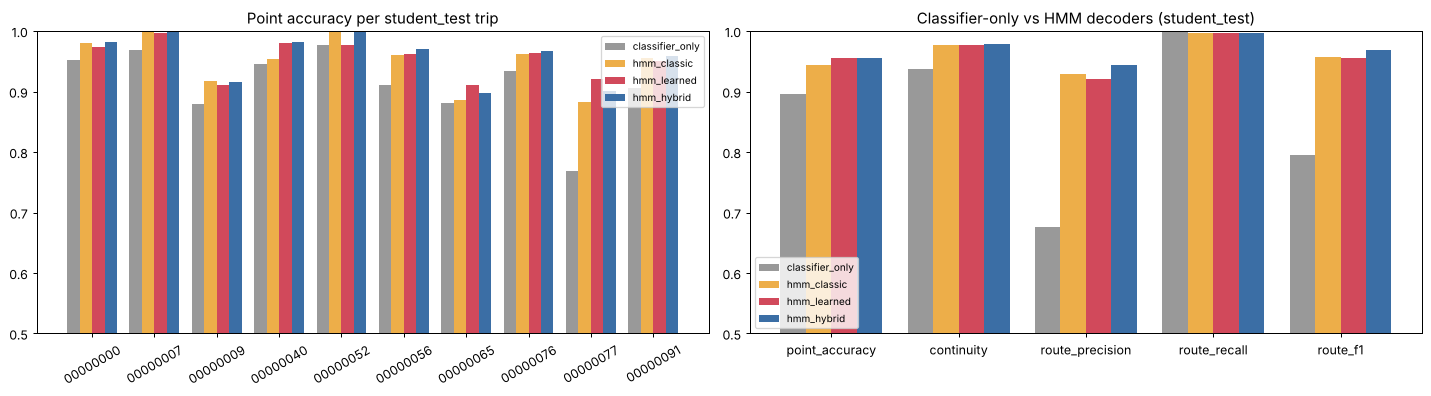

variant,classifier_only,hmm_classic,hmm_learned,hmm_hybrid
trip,,,,
00000000,0.9529,0.9796,0.9732,0.9816
00000007,0.9690,1.0000,0.9963,1.0000
00000009,0.8789,0.9180,0.9113,0.9152
00000040,0.9459,0.9543,0.9810,0.9813
00000052,0.9771,1.0000,0.9771,1.0000
00000056,0.9103,0.9596,0.9621,0.9707
00000065,0.8815,0.8854,0.9102,0.8971
00000076,0.9341,0.9623,0.9630,0.9677
00000077,0.7689,0.8832,0.9200,0.9003


In [11]:
piv = per.pivot(index="trip", columns="variant", values="point_accuracy")[["classifier_only", "hmm_classic", "hmm_learned", "hmm_hybrid"]]
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5)); xx = np.arange(len(piv))
cols = {"classifier_only": "#999999", "hmm_classic": "#edae49", "hmm_learned": "#d1495b", "hmm_hybrid": "#3b6ea5"}
for k, v in enumerate(piv.columns):
    ax[0].bar(xx + (k - 1.5) * .2, piv[v], .2, label=v, color=cols[v])
ax[0].set(xticks=xx, xticklabels=piv.index, ylim=(0.5, 1.0), title="Point accuracy per student_test trip"); ax[0].legend(fontsize=8)
ax[0].tick_params(axis="x", rotation=30)
mets = ["point_accuracy", "continuity", "route_precision", "route_recall", "route_f1"]; xx = np.arange(len(mets))
for k, v in enumerate(summary.index):
    ax[1].bar(xx + (k - 1.5) * .2, summary.loc[v, mets], .2, label=v, color=cols[v])
ax[1].set(xticks=xx, xticklabels=mets, ylim=(0.5, 1.0), title="Classifier-only vs HMM decoders (student_test)"); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()
piv.round(4)

## Step 11 — Visual example (trip with the largest HMM gain)

trip 00000077: mean HMM confidence 0.934; 6.2% of points below 0.6; accuracy on low-confidence points 0.598 vs others 0.920


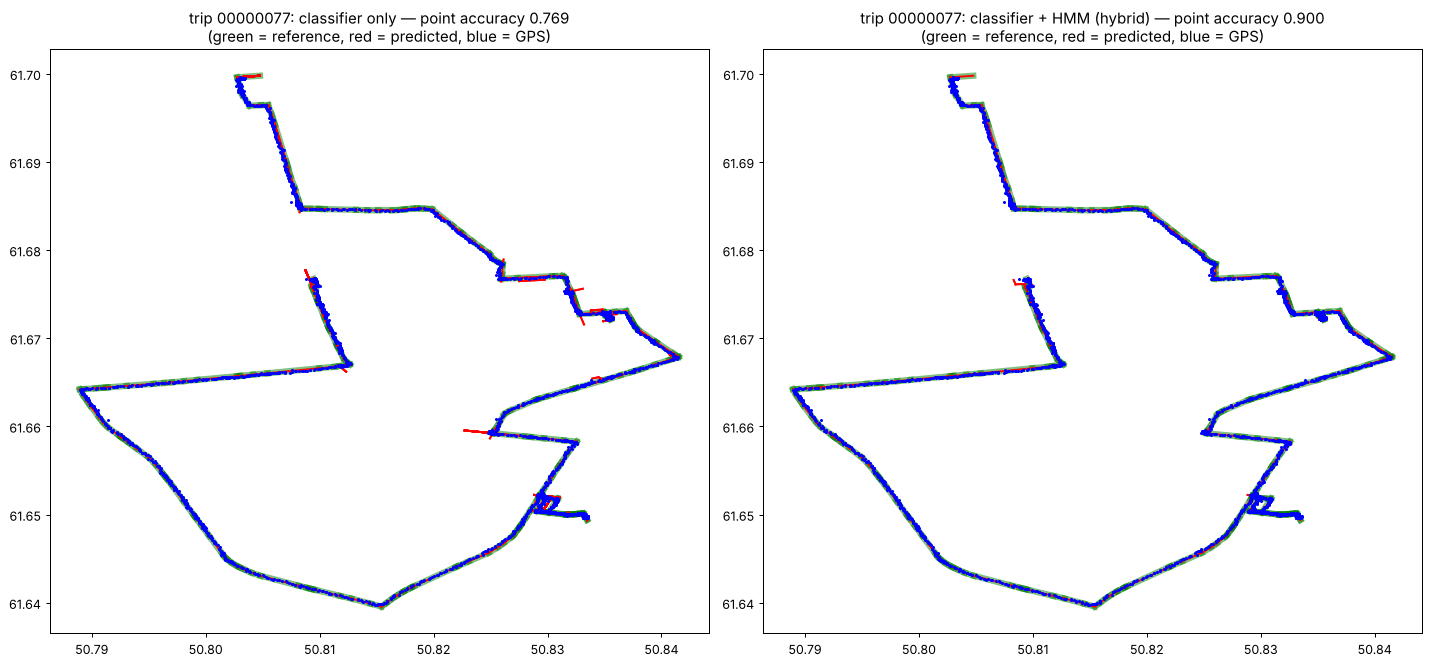

In [12]:
gain = (piv[f"hmm_{SELECTED}"] - piv["classifier_only"]).idxmax()
g = GEO[("student_test", gain)]; nl = g["nodes_lonlat"]
fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, key, title in [(axs[0], "route_clf", "classifier only"), (axs[1], "route_pred", f"classifier + HMM ({SELECTED})")]:
    for e in g["route"]:
        u, v = g["arcs"][e]; ax.plot(nl[[u, v], 0], nl[[u, v], 1], color="green", lw=5, alpha=.5)
    for e in g[key]:
        u, v = g["arcs"][e]; ax.plot(nl[[u, v], 0], nl[[u, v], 1], color="red", lw=1.5)
    ax.scatter(g["lonlat"][:, 0], g["lonlat"][:, 1], s=2, c="blue", zorder=3)
    acc = piv.loc[gain, "classifier_only" if key == "route_clf" else f"hmm_{SELECTED}"]
    ax.set(title=f"trip {gain}: {title} — point accuracy {acc:.3f}\n(green = reference, red = predicted, blue = GPS)")
plt.tight_layout(); plt.show()
low = g["conf"] < 0.6
print(f"trip {gain}: mean HMM confidence {g['conf'].mean():.3f}; {100 * low.mean():.1f}% of points below 0.6; "
      f"accuracy on low-confidence points {(g['pred'][low] == g['label'][low]).mean():.3f} vs others {(g['pred'][~low] == g['label'][~low]).mean():.3f}")

Low-confidence points are where errors concentrate — the confidence is a useful signal, which is why the UI
can colour points by it.

In [13]:
joblib.dump(trans_model, os.path.join(MOD, "transition_model.joblib"))
json.dump(dict(selected_mode=SELECTED, modes=BEST_CFG, unreachable_penalty=-15.0, transition_features=TRANS_FEATURES,
               transition_coefficients=coef.to_dict(), tuning_trips=tune, tuning_classifier_only_accuracy=float(clf_only)),
          open(os.path.join(MOD, "hmm_config.json"), "w"), indent=2)
print("saved: models/notebook/transition_model.joblib, hmm_config.json, results/nb_hmm_*.csv")

saved: models/notebook/transition_model.joblib, hmm_config.json, results/nb_hmm_*.csv


## Summary
- **States** = candidate arcs; **emissions** = tuned classifier probabilities; **transitions** = network vs GPS
  distance consistency (classic), a learned model (learned) or both (hybrid).
- **Gaps:** transition slack grows with Δt and the path search widens after long jumps.
- **Disconnected segments:** fixed penalty instead of impossible transitions → decoding never fails; stitched
  route reports any break it cannot bridge.
- **Tuning without leakage:** out-of-fold probabilities, transition model on half A, decoder weights on half B.
- **Results:** see the comparison table — the HMM raises point accuracy, route continuity and route F1 over the
  classifier alone; the decoder chosen on training trips is the one deployed in the API.